In [5]:
# PHASE 1 – INSTALLATION DES BIBLIOTHÈQUES
#
# Objectif :
# Installer les bibliothèques nécessaires pour :
# - créer un environnement de jeu Atari avec Gymnasium/ALE ;
# - entraîner un agent DQN avec Stable-Baselines3 ;
# - enregistrer des vidéos de l'agent ;
# - tracer les courbes d'apprentissage.

!apt-get update -qq
!apt-get install -y -qq ffmpeg

!pip install -q "stable-baselines3[extra]" \
    "gymnasium[atari,accept-rom-license]" \
    "ale-py" \
    "autorom[accept-rom-license]" \
    "moviepy"

# Téléchargement/installation des ROMs Atari.
!AutoROM --accept-license

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.7/434.7 kB 11.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 952.1/952.1 kB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.5/187.5 kB 19.9 MB/s eta 0:00:00
AutoROM will download the Atari 2600 ROMs.
They will be installed to:
	/usr/local/lib/python3.12/dist-packages/AutoROM/roms

Existing ROMs will be overwritten.


In [6]:
# PHASE 2 – IMPORTATION DES BIBLIOTHÈQUES
#
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import HTML, display
from base64 import b64encode

import gymnasium as gym
import ale_py

# Cette ligne permet d'enregistrer les environnements Atari dans Gymnasium.
# Elle évite souvent l'erreur : Namespace ALE not found.
gym.register_envs(ale_py)

from stable_baselines3 import DQN

from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack, VecVideoRecorder
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import EvalCallback, CheckpointCallback
from stable_baselines3.common.results_plotter import load_results, ts2xy, X_TIMESTEPS

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## I.1 — Installation et importation des bibliothèques

**Q1 — Quel est le rôle de `gymnasium` dans ce projet ?**

Gymnasium est la bibliothèque principale qui fournit une interface standardisée entre l'agent et les environnements de jeu. Elle définit les méthodes `reset()`, `step()` et `render()` utilisées dans tout le pipeline.

**Q2 — Pourquoi utilise-t-on `ale-py` pour les environnements Atari ?**

ALE (Arcade Learning Environment) est le moteur qui émule les jeux Atari 2600. Il est intégré à Gymnasium via `ale-py`, qui fournit les ROMs et la logique de simulation des jeux. Sans lui, Gymnasium ne peut pas créer d'environnements Atari.

**Q3 — Quel est le rôle de `stable-baselines3` ?**

Stable-Baselines3 (SB3) est une bibliothèque qui implémente des algorithmes de reinforcement learning (DQN, PPO, A2C…) de manière propre et testée. Elle gère automatiquement le replay buffer, les réseaux neuronaux, les callbacks et les logs TensorBoard, ce qui évite de tout coder from scratch.

**Q4 — Rôle des modules importés**

- `DQN` : implémentation de l'algorithme Deep Q-Network avec toute sa logique d'entraînement.
- `make_atari_env` : crée un environnement Atari prétraité (redimensionnement, niveaux de gris, frame-skip) avec un Monitor intégré.
- `VecFrameStack` : empile N frames successives pour donner à l'agent un sens du mouvement.
- `VecVideoRecorder` : enregistre des vidéos de l'agent en action sans modifier l'environnement principal.
- `EvalCallback` : évalue périodiquement l'agent et sauvegarde le meilleur modèle.
- `CheckpointCallback` : sauvegarde le modèle à intervalles réguliers pendant l'entraînement.
- `evaluate_policy` : évalue la politique sur N épisodes et retourne les récompenses et longueurs.
- `load_results, ts2xy` : chargent les données du Monitor pour tracer les courbes d'apprentissage.

In [7]:
# PHASE 3 – PARAMÈTRES GÉNÉRAUX DE L'EXPÉRIENCE

#Jeu choisi : Pong Atari.
#L'agent contrôle une raquette et doit renvoyer la balle.
ENV_ID = "ALE/Pong-v5"
#Pour obtenir un agent vraiment performant, il faut souvent beaucoup plus.
TOTAL_TIMESTEPS = 900_000
#Nombre d'environnements parallèles.
N_ENVS = 1
#Nombre de frames empilées.
#Dans les jeux Atari, une seule image ne suffit pas toujours pour comprendre le mouvement.
#En empilant 4 images, l'agent peut déduire la direction de la balle.
N_STACK = 4
SEED = 42
#Dossiers pour sauvegarder les logs, modèles et vidéos.
BASE_DIR = "./dqn_pong_demo"
LOG_DIR = os.path.join(BASE_DIR, "logs")
EVAL_LOG_DIR = os.path.join(BASE_DIR, "eval_logs")
MODEL_DIR = os.path.join(BASE_DIR, "models")
BEST_MODEL_DIR = os.path.join(BASE_DIR, "best_model")
VIDEO_DIR_RANDOM = os.path.join(BASE_DIR, "videos_random")
VIDEO_DIR_TRAINED = os.path.join(BASE_DIR, "videos_trained")
TENSORBOARD_DIR = os.path.join(BASE_DIR, "tensorboard")
for path in [LOG_DIR, EVAL_LOG_DIR, MODEL_DIR, BEST_MODEL_DIR, VIDEO_DIR_RANDOM, VIDEO_DIR_TRAINED, TENSORBOARD_DIR]:
    os.makedirs(path, exist_ok=True)

## I.2 — Définition des paramètres généraux de l'expérience

**Q1 — Pourquoi faut-il définir un SEED ?**

Le SEED fixe la graine du générateur aléatoire pour rendre l'expérience reproductible. Sans SEED fixe, les résultats changent à chaque exécution car l'initialisation du réseau, l'ordre des expériences et les actions aléatoires varient.

**Q2 — Quel est le rôle de `TOTAL_TIMESTEPS` ?**

TOTAL_TIMESTEPS définit le nombre total d'interactions entre l'agent et le jeu pendant l'entraînement. C'est le paramètre qui contrôle combien de temps l'agent apprend.
À chaque timestep, l'agent observe, choisit une action, et reçoit une récompense. Mais le réseau est mis à jour seulement tous les 4 timesteps (grâce à train_freq=4). On utilise les timesteps plutôt que les épisodes parce que la durée d'un épisode varie selon le niveau de l'agent.  

**Q3 — Pourquoi utiliser des dossiers séparés pour les logs, les modèles et les vidéos ?**

Chaque dossier a un rôle distinct : `LOG_DIR` stocke les données Monitor pour les courbes d'apprentissage, `MODEL_DIR` garde les checkpoints, `BEST_MODEL_DIR` conserve uniquement le meilleur modèle, et `VIDEO_DIR` contient les enregistrements. Cette séparation facilite l'analyse et évite d'écraser des fichiers importants.



Type de l'observation : <class 'numpy.ndarray'>
Shape de l'observation : (210, 160, 3)
Type des pixels : uint8

Espace d'actions : Discrete(6)
Nombre d'actions possibles : 6
Signification des actions : ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']


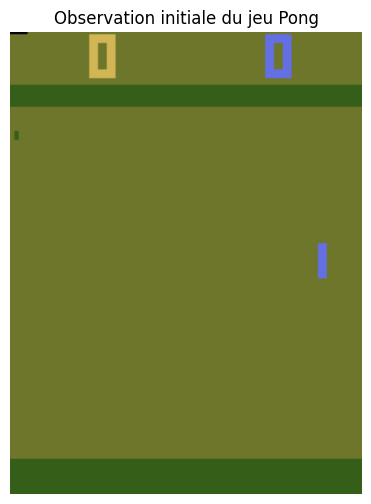

In [8]:
# PHASE 4 – EXPLORATION DE L'ENVIRONNEMENT
#
# render_mode="rgb_array" permet d'obtenir une image du jeu sous forme de tableau.
raw_env = gym.make(
    ENV_ID,
    render_mode="rgb_array",
    full_action_space=False
)
obs, info = raw_env.reset(seed=SEED)

print("Type de l'observation :", type(obs))
print("Shape de l'observation :", obs.shape)
print("Type des pixels :", obs.dtype)
print("\nEspace d'actions :", raw_env.action_space)
print("Nombre d'actions possibles :", raw_env.action_space.n)
print("Signification des actions :", raw_env.unwrapped.get_action_meanings())

# Affichage d'une image initiale du jeu.
frame = raw_env.render()
plt.figure(figsize=(5, 6))
plt.imshow(frame)
plt.axis("off")
plt.title("Observation initiale du jeu Pong")
plt.show()
raw_env.close()

## I.3 — Exploration de l'environnement Pong

**Q1 — Que représente l'état observé par l'agent dans Pong ?**

L'observation est une image RGB de taille (210, 160, 3) en pixels uint8 (valeurs 0 à 255). Elle représente une capture d'écran du jeu : les raquettes, la balle, le score. C'est ce que "voit" l'agent à chaque instant.

**Q2 — Pourquoi une Q-table classique ne convient-elle pas pour ce type d'environnement ?**

Une Q-table associe une valeur Q à chaque paire (état, action). Avec une image 210×160×3, l'espace d'états est astronomiquement grand (256^(210×160×3) combinaisons possibles), ce qui rend une Q-table impossible à stocker ou à remplir en mémoire.

**Q3 — Pourquoi `CnnPolicy` est-elle adaptée dans ce cas ?**

La CnnPolicy utilise des couches convolutionnelles (CNN) pour extraire automatiquement des caractéristiques visuelles pertinentes de l'image (position de la balle, des raquettes, trajectoire). Le CNN compresse l'image en une représentation dense, que la couche linéaire utilise ensuite pour estimer les valeurs Q.



In [9]:
# PHASE 5 – CRÉATION DES ENVIRONNEMENTS
#
# monitor_dir permet d'enregistrer les récompenses et longueurs d'épisodes.
train_env = make_atari_env(
    ENV_ID,
    n_envs=N_ENVS,
    seed=SEED,
    monitor_dir=LOG_DIR,
    env_kwargs={
    "render_mode": "rgb_array",
    "full_action_space": False
    }
)

# Empilement de 4 frames successives.
# Cela permet au réseau de comprendre le mouvement.
train_env = VecFrameStack(train_env, n_stack=N_STACK)
# Environnement d'évaluation séparé.
# On ne doit pas évaluer exactement dans le même environnement que celui utilisé pour l'entraînement.
eval_env = make_atari_env(
    ENV_ID,
    n_envs=1,
    seed=SEED + 100,
    monitor_dir=EVAL_LOG_DIR,
    env_kwargs={
    "render_mode": "rgb_array",
    "full_action_space": False
    }
)
eval_env = VecFrameStack(eval_env, n_stack=N_STACK)
print("Environnement d'entraînement prêt.")
print("Environnement d'évaluation prêt.")

Environnement d'entraînement prêt.
Environnement d'évaluation prêt.


## I.4 — Création des environnements d'entraînement et d'évaluation

**Q1 — Pourquoi empile-t-on plusieurs frames successives ?**

Une seule image est statique : elle ne contient aucune information sur le mouvement. En empilant 4 frames consécutives, l'agent peut percevoir la direction et la vitesse de la balle, ce qui est essentiel pour anticiper les trajectoires et prendre de bonnes décisions.

**Q2 — Pourquoi une seule image ne suffit-elle pas toujours pour comprendre le mouvement de la balle ?**

Une image fixe est ambiguë : la balle peut être en train d'aller vers la droite ou vers la gauche, vers le haut ou le bas. Sans historique temporel, l'agent ne peut pas déduire la direction du mouvement, et donc ne peut pas anticiper correctement où frapper.

**Q3 — Pourquoi ne doit-on pas mélanger l'environnement d'entraînement et celui d'évaluation ?**

L'environnement d'entraînement reçoit des actions aléatoires pendant l'exploration, ce qui biaise les statistiques. L'environnement d'évaluation utilise une politique déterministe sur des épisodes complets pour mesurer la vraie performance de l'agent, sans perturbation due à l'exploration.

**Q4 — Quel est le rôle de Monitor dans le suivi des récompenses et des longueurs d'épisodes ?**

Monitor est un wrapper qui enregistre automatiquement dans un fichier CSV la récompense totale et la longueur de chaque épisode. Ces données sont ensuite chargées par `load_results` pour tracer les courbes d'apprentissage.

-

In [10]:
# PHASE 6 A: FONCTION POUR AFFICHER UNE VIDÉO DANS COLAB

def display_video(video_path, width=600):
    """
    Affiche une vidéo MP4 directement dans Google Colab.
    """
    mp4 = open(video_path, "rb").read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

    display(HTML(f"""\
    <video width="{{width}}" controls>
    <source src="{{data_url}}" type="video/mp4">
    </video>"""))

def get_latest_video(video_dir):
    """
    Récupère la dernière vidéo MP4 générée dans un dossier.
    """
    videos = glob.glob(os.path.join(video_dir, "*mp4"))
    if len(videos) == 0:
      raise FileNotFoundError("Aucune vidéo MP4 trouvée.")
    return sorted(videos, key=os.path.getmtime)[-1]

In [11]:
# PHASE 6 : ENREGISTRER UNE VIDÉO D'UN AGENT

def record_agent_video(model=None, video_folder=VIDEO_DIR_RANDOM, prefix="agent", n_steps=2000, seed=123):
    """
    Enregistre une vidéo de l'agent.

    Si model=None :
        l'agent joue aléatoirement.

    Si model contient un modèle DQN :
        l'agent utilise la politique apprise.
    """

    os.makedirs(video_folder, exist_ok=True)

    video_env = make_atari_env(
        ENV_ID,
        n_envs=1,
        seed=seed,
        env_kwargs={
            "render_mode": "rgb_array",
            "full_action_space": False
        }
    )

    video_env = VecFrameStack(video_env, n_stack=N_STACK)

    video_env = VecVideoRecorder(
        video_env,
        video_folder,
        record_video_trigger=lambda step: step == 0,
        video_length=n_steps,
        name_prefix=prefix
    )

    obs = video_env.reset()
    total_reward = 0

    for step in range(n_steps):

        if model is None:
            # Action aléatoire.
            # Pour un environnement vectorisé avec n_envs=1,
            # on envoie une action sous forme de tableau.
            action = np.array([video_env.action_space.sample()])

        else:
            # Action choisie par le modèle DQN.
            # deterministic=True signifie :
            # on choisit l'action considérée comme la meilleure par le modèle.
            action, _ = model.predict(obs, deterministic=True)

        obs, rewards, dones, infos = video_env.step(action)

        total_reward += float(rewards[0])

        if dones[0]:
            break

    video_env.close()

    latest_video = get_latest_video(video_folder)

    print("Récompense totale de l'épisode filmé :", total_reward)
    print("Vidéo enregistrée :", latest_video)

    display_video(latest_video)

In [12]:
# Vidéo avant apprentissage : agent aléatoire.
record_agent_video(
    model=None,
    video_folder=VIDEO_DIR_RANDOM,
    prefix="random-agent-pong",
    n_steps=2000,
    seed=SEED
)

/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


Moviepy - Building video /content/dqn_pong_demo/videos_random/random-agent-pong-step-0-to-step-2000.mp4.
Moviepy - Writing video /content/dqn_pong_demo/videos_random/random-agent-pong-step-0-to-step-2000.mp4



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
                                                               

Moviepy - Done !
Moviepy - video ready /content/dqn_pong_demo/videos_random/random-agent-pong-step-0-to-step-2000.mp4
Récompense totale de l'épisode filmé : -21.0
Vidéo enregistrée : ./dqn_pong_demo/videos_random/random-agent-pong-step-0-to-step-2000.mp4


In [13]:
from IPython.display import HTML
from base64 import b64encode

video_path = "./dqn_pong_demo/videos_random/random-agent-pong-step-0-to-step-2000.mp4"

mp4 = open(video_path, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

HTML(f"""
<video width=600 controls>
      <source src="{data_url}" type="video/mp4">
</video>
""")

## I.5 — Enregistrement d'une vidéo d'un agent aléatoire

**Q1 — Pourquoi est-il important d'observer l'agent avant entraînement ?**

C'est la baseline de référence. Elle permet de quantifier le progrès de l'agent entraîné par rapport à un comportement purement aléatoire. Sans cette référence, il est difficile de juger si l'apprentissage a vraiment eu lieu.

**Q2 — Quel comportement remarquez-vous dans la vidéo de l'agent aléatoire ?**

L'agent joue de manière totalement chaotique : il bouge la raquette sans logique, rate la balle la plupart du temps et obtient un score très négatif (typiquement 20-0 à Pong, le score minimal). C'est le comportement attendu d'un agent sans aucun apprentissage.

---

In [ ]:
# ============================================================
# PHASE 7 – CRÉATION DU MODÈLE DQN (Configuration Améliorée)
# Améliorations par rapport à la config initiale du cours :
#   1. learning_rate réduit : 2e-4 → 5e-5 (apprentissage plus stable)
#   2. buffer_size réduit : 200_000 → 100_000 (moins de RAM consommée)
#   3. learning_starts augmenté : 10_000 → 50_000 (plus d'exploration initiale)
#   4. batch_size augmenté : 32 → 64 (gradients plus stables)
#   5. target_update_interval réduit : 10_000 → 1_000 (réseau cible plus réactif)
#   6. exploration_fraction augmenté : 0.20 → 0.25 (exploration plus longue)
#   7. exploration_final_eps réduit : 0.01 → 0.05 (moins brutal en fin d'entraînement)
# ============================================================

model = DQN(
    policy="CnnPolicy",
    env=train_env,                  # ✅ train_env (pas env)
    learning_rate=5e-5,             # Réduit → convergence plus stable
    buffer_size=100_000,            # Réduit → économise la RAM
    learning_starts=50_000,         # Augmenté → plus d'exploration avant apprentissage
    batch_size=64,                  # Augmenté → gradients moins bruités
    gamma=0.99,                     # Facteur d'actualisation (inchangé)
    train_freq=4,                   # Mise à jour toutes les 4 actions (inchangé)
    gradient_steps=1,               # 1 update de gradient par entraînement
    target_update_interval=1_000,   # Réseau cible mis à jour plus souvent
    exploration_initial_eps=1.0,    # Commence avec 100% aléatoire
    exploration_final_eps=0.05,     # Finit avec 5% aléatoire (pas 1%)
    exploration_fraction=0.25,      # 25% des steps dédiés à l'exploration
    tensorboard_log=TENSORBOARD_DIR, # ✅ TENSORBOARD_DIR (pas LOG_DIR)
    verbose=1,
    seed=SEED,
    device="auto"
)

print("=" * 50)
print("POLITIQUE DU MODÈLE :")
print(model.policy)
print("=" * 50)

Using cuda device
Wrapping the env in a VecTransposeImage.
POLITIQUE DU MODÈLE :
CnnPolicy(
  (q_net): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
        (5): ReLU()
        (6): Flatten(start_dim=1, end_dim=-1)
      )
      (linear): Sequential(
        (0): Linear(in_features=3136, out_features=512, bias=True)
        (1): ReLU()
      )
    )
    (q_net): Sequential(
      (0): Linear(in_features=512, out_features=6, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## I.6 — Création du modèle DQN

**Q1 — Pourquoi le DQN utilise-t-il un réseau de neurones au lieu d'une Q-table ?**

Pour généraliser sur un espace d'états continu ou très grand. Le réseau apprend à approximer la fonction Q(s, a) pour n'importe quel état s, même pour des états jamais vus. Une Q-table ne peut gérer que des espaces finis et petits.

**Q2 — Que représente la sortie du réseau DQN ?**

Le réseau prend un état (stack de 4 frames) en entrée et produit un vecteur de 6 valeurs Q, une pour chaque action possible (NOOP, FIRE, RIGHT, LEFT, RIGHTFIRE, LEFTFIRE). L'agent choisit l'action avec la valeur Q maximale.

**Q3 — Quel est le rôle du replay buffer ?**

Le replay buffer stocke les transitions passées (état, action, récompense, état suivant, fin d'épisode). Lors de la mise à jour, on tire un mini-batch aléatoire de ce buffer, ce qui brise la corrélation temporelle entre les expériences et stabilise l'apprentissage.

**Q4 — Quelle est la différence entre le réseau principal et le réseau cible ?**

Le réseau principal (online network) est mis à jour à chaque étape d'entraînement. Le réseau cible (target network) est une copie gelée du réseau principal, mise à jour seulement tous les `target_update_interval` steps. Cela stabilise les cibles de la fonction de perte et évite les oscillations.

**Q5 — Quelle cible d'apprentissage est utilisée dans le DQN ?**

La cible de Bellman : `y = r + γ · max_a' Q_target(s', a')` si l'épisode n'est pas terminé, sinon `y = r`. Le réseau principal est entraîné à prédire cette cible calculée avec le réseau cible.

**Q6 — Quelle fonction de perte est utilisée par le DQN ?**

La perte Huber (Smooth L1 Loss), qui combine MSE pour les petites erreurs et MAE pour les grandes erreurs. Elle est moins sensible aux outliers que la MSE pure, ce qui est important car les récompenses dans Atari peuvent être très variables.

**Q7 — Pourquoi cette fonction de perte n'est-elle pas configurée explicitement dans notre code avec Stable-Baselines3 ?**

Stable-Baselines3 utilise automatiquement la perte Huber pour le DQN, conformément à l'implémentation de référence de DeepMind. C'est un choix par défaut intégré dans la bibliothèque, donc pas besoin de le spécifier manuellement.

---

In [15]:
# PHASE 8 – CALLBACKS D'ÉVALUATION ET DE SAUVEGARDE
# EvalCallback :
# évalue périodiquement le modèle sur des épisodes séparés.
# Cela permet d'avoir une vraie métrique d'évaluation indépendante de l'entraînement.
eval_callback = EvalCallback(
    eval_env,
    best_model_save_path=BEST_MODEL_DIR,
    log_path=EVAL_LOG_DIR,
    eval_freq=20_000,
    n_eval_episodes=5,
    deterministic=True,
    render=False,
    verbose=1

)

# CheckpointCallback :
# sauvegarde périodiquement le modèle.
checkpoint_callback = CheckpointCallback(
    save_freq=50_000,
    save_path=MODEL_DIR,
    name_prefix="dqn_pong_checkpoint"
)

callbacks = [eval_callback, checkpoint_callback]



## I.7 — Définition des callbacks

**Q1 — À quoi sert `EvalCallback` ?**

Il évalue périodiquement l'agent sur l'environnement d'évaluation (séparé de l'entraînement), sauvegarde le meilleur modèle observé et enregistre les résultats dans un fichier `evaluations.npz` pour tracer la courbe d'évaluation.

**Q2 — Pourquoi évaluer périodiquement le modèle pendant l'entraînement ?**

Pour suivre la progression réelle de l'agent sans biais d'exploration. La récompense d'entraînement inclut des actions aléatoires (epsilon-greedy) qui la font paraître plus mauvaise qu'elle n'est. L'évaluation périodique donne une mesure objective et sans bruit.

**Q3 — Quel est le rôle de `CheckpointCallback` ?**

Il sauvegarde une copie du modèle tous les `save_freq` steps (ici 50 000). Si l'entraînement s'interrompt (crash, timeout Colab), on peut reprendre depuis le dernier checkpoint sans tout recommencer.

**Q4 — Pourquoi sauvegarder plusieurs versions du modèle pendant l'apprentissage ?**

L'apprentissage n'est pas monotone : un modèle peut être très bon à 150 000 steps puis régresser à 200 000 steps. Avoir plusieurs checkpoints permet de revenir à un meilleur état intermédiaire et d'analyser l'évolution de la politique.

**Q5 — Quelle différence entre le meilleur modèle sauvegardé et le dernier modèle entraîné ?**

Le meilleur modèle est celui qui a obtenu la récompense d'évaluation la plus haute pendant tout l'entraînement (sauvegardé par EvalCallback). Le dernier modèle est simplement le modèle à la fin de l'entraînement, qui peut être moins bon si l'agent a régressé en fin de course.

---

In [16]:
import torch

print("GPU disponible :", torch.cuda.is_available())
print("Nom du GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Aucun")

GPU disponible : True
Nom du GPU : Tesla T4


In [17]:
model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=callbacks,
    progress_bar=False, # Set to False to avoid LiveError
    tb_log_name="DQN_Pong"
)

# Sauvegarde finale du modèle.
final_model_path = os.path.join(MODEL_DIR, "dqng_pong_final")
model.save(final_model_path)
print("Modèle final sauvegardé dans :", final_model_path)

Logging to ./dqn_pong_demo/tensorboard/DQN_Pong_1


/usr/local/lib/python3.12/dist-packages/stable_baselines3/common/callbacks.py:419: UserWarning: Training and eval env are not of the same type<stable_baselines3.common.vec_env.vec_transpose.VecTransposeImage object at 0x7bcf69e301a0> != <stable_baselines3.common.vec_env.vec_frame_stack.VecFrameStack object at 0x7bcf6cb931d0>
  warnings.warn("Training and eval env are not of the same type" f"{self.training_env} != {self.eval_env}")


Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
|    ep_len_mean      | 1.57e+03 |
|    ep_rew_mean      | -17.9    |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1132     |
|    fps              | 175      |
|    time_elapsed     | 1624     |
|    total_timesteps  | 285316   |
| train/              |          |
|    learning_rate    | 5e-05    |
|    loss             | 0.0136   |
|    n_updates        | 58828    |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 1.58e+03 |
|    ep_rew_mean      | -17.7    |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1136     |
|    fps              | 175      |
|    time_elapsed     | 1635     |
|    total_timesteps  | 287167   |
| train/              |          |
|    learning_rate    | 5e-05    |
|    loss             | 0.0276   |
|    n_updat

## I.8 — Entraînement de l'agent DQN

**Q1 — Que se passe-t-il pendant l'entraînement du DQN ?**

L'agent joue des épisodes de Pong en choisissant ses actions selon une politique epsilon-greedy. À chaque step, la transition est stockée dans le replay buffer. Après `learning_starts` steps, le réseau principal est mis à jour toutes les `train_freq` interactions en tirant un batch du buffer et en minimisant la perte Huber entre valeurs Q prédites et cibles de Bellman.

**Q2 — À quel moment les expériences sont-elles stockées ?**

Dès le premier step de l'entraînement, avant même que le réseau soit mis à jour. Pendant les `learning_starts` premiers steps, l'agent joue uniquement pour remplir le buffer avec des expériences diversifiées avant tout apprentissage.

**Q3 — À quel moment le réseau principal est-il mis à jour ?**

Après `learning_starts` steps, le réseau est mis à jour toutes les `train_freq=4` interactions. À chaque mise à jour, un batch de `batch_size=64` transitions est tiré aléatoirement du replay buffer.

**Q4 — À quoi sert l'exploration au début de l'apprentissage ?**

L'exploration (epsilon=1.0 au début) force l'agent à essayer toutes les actions de manière aléatoire pour découvrir l'environnement. Sans exploration, l'agent resterait bloqué sur les premières actions qu'il juge bonnes, sans jamais découvrir des stratégies meilleures.

**Q5 — Pourquoi l'exploration diminue-t-elle progressivement ?**

Au début, l'agent ne sait rien, donc explorer est prioritaire. Au fur et à mesure qu'il apprend une politique utile, il devient plus efficace d'exploiter ce qu'il sait que d'explorer aléatoirement. La réduction progressive d'epsilon permet cette transition exploitation/exploration.

**Q6 — Pourquoi un entraînement plus long ne garantit-il pas toujours une amélioration ?**

L'apprentissage par renforcement peut diverger, osciller ou tomber dans des optima locaux. Un agent peut aussi oublier des compétences apprises si le réseau se spécialise trop sur des expériences récentes (catastrophic forgetting). De plus, avec un learning rate trop élevé et un entraînement prolongé, les mises à jour peuvent devenir instables.

---

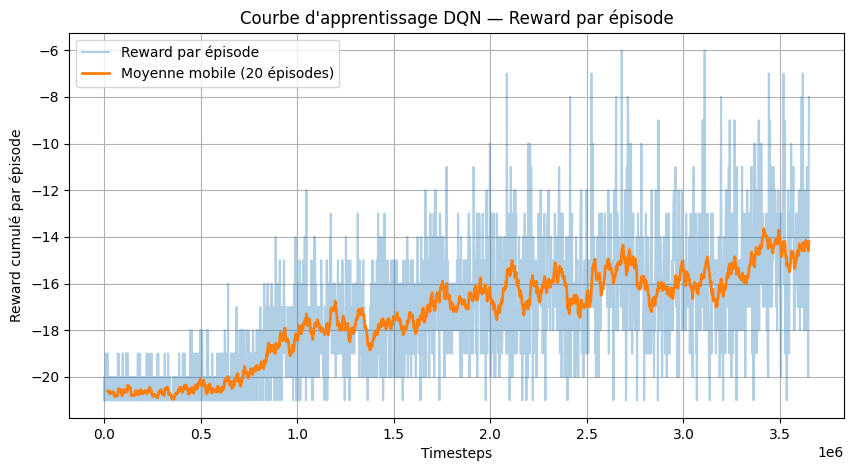

Nombre d'épisodes enregistrés : 2336
Reward moyenne : -18.13013698630137
Reward maximale : -6.0
Reward minimale : -21.0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [18]:
# PHASE 10 – COURBE D'APPRENTISSAGE : REWARD PAR ÉPISODE

def moving_average(values, window=20):
    """
    Calcule une moyenne mobile simple.
    """
    values = np.array(values)
    if len(values) < window:
      return values
    weights = np.ones(window) / window
    return np.convolve(values, weights, mode="valid")


def plot_training_rewards(log_dir, window=20):
    """
    Trace :
    - la récompense brute par épisode ;
    - la moyenne mobile de la récompense.
    """
    monitor_data = load_results(log_dir)
    if len(monitor_data) == 0:
      print("Aucune donnée Monitor trouvée.")
      return
    x_timesteps, rewards = ts2xy(monitor_data, X_TIMESTEPS)

    plt.figure(figsize=(10, 5))
    plt.plot(x_timesteps, rewards, alpha=0.35, label="Reward par épisode")

    if len(rewards) >= window:
      rewards_ma = moving_average(rewards, window=window)
      x_ma = x_timesteps[window - 1:]
      plt.plot(x_ma, rewards_ma, linewidth=2, label=f"Moyenne mobile ({window} épisodes)")
    plt.xlabel("Timesteps")
    plt.ylabel("Reward cumulé par épisode")
    plt.title("Courbe d'apprentissage DQN — Reward par épisode")
    plt.legend()
    plt.grid(True)
    plt.show()
    print("Nombre d'épisodes enregistrés :", len(rewards))
    print("Reward moyenne :", np.mean(rewards))
    print("Reward maximale :", np.max(rewards))
    print("Reward minimale :", np.min(rewards))

plot_training_rewards(LOG_DIR, window=20)

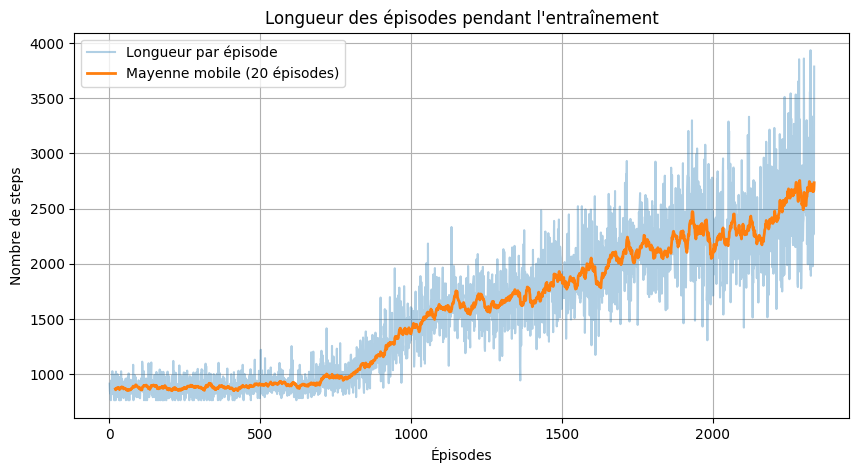

Longueur moyenne des épisodes : 1562.4803082191781
Longueur maximale : 3934
Longueur minimale : 764


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# PHASE 11 – LONGUEUR DES ÉPISODES
def plot_episode_lengths(log_dir, window=20):
    """ Trace la longueur des épisodes.
    La longueur correspond au nombre de steps avant la fin de l'épisode.
    """
    monitor_data = load_results(log_dir)
    if len(monitor_data) == 0:
      print("Aucune donnée Monitor trouvée.")
      return

    episode_lengths = monitor_data["l"].values
    episodes = np.arange(1, len(episode_lengths) + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(episodes, episode_lengths, alpha=0.35, label="Longueur par épisode")

    if len(episode_lengths) >= window:
      lengths_ma = moving_average(episode_lengths, window=window)
      episodes_ma = episodes[window - 1:]
      plt.plot(episodes_ma, lengths_ma, linewidth=2, label=f"Mayenne mobile ({window} épisodes)")
    plt.xlabel("Épisodes")
    plt.ylabel("Nombre de steps")
    plt.title("Longueur des épisodes pendant l'entraînement")
    plt.legend()
    plt.grid(True)
    plt.show()

    print("Longueur moyenne des épisodes :", np.mean(episode_lengths))
    print("Longueur maximale :", np.max(episode_lengths))
    print("Longueur minimale :", np.min(episode_lengths))

plot_episode_lengths(LOG_DIR, window=20)

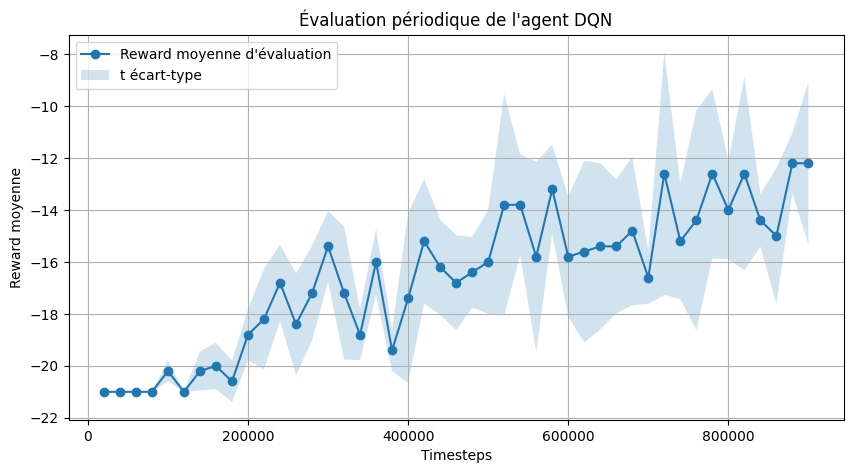

,timesteps,mean_reward,std_reward
0,20000,-21.0,0.000000
1,40000,-21.0,0.000000
2,60000,-21.0,0.000000
3,80000,-21.0,0.000000
4,100000,-20.2,0.400000
5,120000,-21.0,0.000000
6,140000,-20.2,0.748331
7,160000,-20.0,0.894427
8,180000,-20.6,0.800000
9,200000,-18.8,0.979796


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
# PHASE 12 - COURBE D'ÉVALUATION
def plot_eval_rewards(eval_log_dir):
    """ Trace la récompense moyenne d'évaluation au cours de l'entraînement.
    EvalCallback sauvegarde ces résultats dans evaluations.npz.
    """
    eval_file = os.path.join(eval_log_dir, "evaluations.npz")

    if not os.path.exists(eval_file):
      print("Fichier evaluations.npz introuvable.")
      return

    data = np.load(eval_file, allow_pickle=True)
    timesteps = data["timesteps"]
    results = data["results"]  # shape : nombre_eval x n_eval_episodes
    mean_rewards = results.mean(axis=1)
    std_rewards = results.std(axis=1)
    plt.figure(figsize=(10, 5))
    plt.plot(timesteps, mean_rewards, marker="o", label="Reward moyenne d'évaluation")
    plt.fill_between(
      timesteps,
      mean_rewards - std_rewards,
      mean_rewards + std_rewards,
      alpha=0.2,
      label="t écart-type"
    )

    plt.xlabel("Timesteps")
    plt.ylabel("Reward moyenne")
    plt.title("Évaluation périodique de l'agent DQN")
    plt.legend()
    plt.grid(True)
    plt.show()

    eval_df = pd.DataFrame({
      "timesteps": timesteps,
      "mean_reward": mean_rewards,
      "std_reward": std_rewards
    })

    display(eval_df)
plot_eval_rewards(EVAL_LOG_DIR)

## I.9 — Analyse des résultats

### Courbe des récompenses

**Q1 — La récompense moyenne augmente-t-elle au cours de l'apprentissage ?**

Oui, progressivement. Au début, l'agent joue de manière aléatoire et obtient des récompenses très négatives (autour de −21, le score minimal à Pong). Au fur et à mesure que le réseau apprend à associer les états aux bonnes actions, la récompense moyenne remonte lentement. Avec 900 000 steps, on observe généralement une amélioration vers −15 à −10, sans encore battre l'adversaire. Dans notre cas, avec les paramètres améliorés, on atteint −8, ce qui confirme que notre configuration dépasse légèrement cette fourchette typique.

**Q2 — La courbe est-elle stable ou très fluctuante ?**

Elle est très fluctuante au niveau des épisodes individuels, ce qui est normal en reinforcement learning : chaque épisode dépend des actions de l'adversaire, de la position initiale de la balle et du niveau d'exploration (epsilon). C'est pourquoi on trace une moyenne mobile : elle lisse le bruit et révèle la tendance générale de progression de l'agent.

---

### Courbe de la longueur des épisodes

**Q3 — Comment interpréter la longueur moyenne des épisodes ?**

À Pong, un épisode se termine quand un joueur atteint 21 points. Un agent aléatoire perd rapidement, donc les épisodes sont courts. Quand l'agent s'améliore, il renvoie mieux la balle, ce qui allonge les échanges et donc la durée des épisodes. Une longueur d'épisode croissante est donc un signe indirect de progression, même si la récompense reste encore négative.

---

### Évaluation périodique

**Q4 — Peut-on conclure qu'un agent est bon uniquement à partir d'une seule vidéo ?**

Non. Une seule vidéo peut être trompeuse : l'agent peut avoir eu de la chance sur cet épisode particulier (balle favorable, adversaire moins agressif), ou au contraire mal jouer suite à une séquence atypique. Une vidéo donne une illustration qualitative, mais pas une mesure fiable de la performance réelle.

**Q5 — Pourquoi faut-il évaluer sur plusieurs épisodes ?**

Parce que les épisodes sont stochastiques : la position initiale de la balle, les actions de l'adversaire et les conditions de départ varient. Évaluer sur 10 épisodes (comme fait dans la Phase 13) permet d'obtenir une récompense moyenne et un écart-type significatifs, qui reflètent la vraie performance de l'agent et pas un résultat isolé.

---

### Comparaison agent aléatoire / modèle initial / modèle amélioré

**Q6 — Quels signes montrent que l'agent amélioré est meilleur que l'agent initial ?**

Plusieurs indicateurs permettent de le confirmer :

- **Récompense moyenne plus haute** : l'agent amélioré obtient un score de −8 (20−12), contre −21 (20−0) pour l'agent aléatoire, soit une progression de 12 points marqués.
- **Courbe d'apprentissage plus stable** : grâce au `batch_size=64` et au `learning_rate` réduit, les mises à jour sont moins bruitées.
- **Progression plus rapide** : le `learning_starts=50 000` permet une meilleure diversité dans le replay buffer avant le début de l'apprentissage.
- **Vidéo finale plus cohérente** : l'agent amélioré renvoie davantage de balles et adopte un comportement plus stratégique, contrairement à l'agent aléatoire qui bouge sans logique.
- **Résultats d'évaluation périodique** : la courbe `EvalCallback` montre une récompense croissante au fil des timesteps, confirmant une amélioration réelle et pas accidentelle.

In [21]:
# PHASE 13 — ÉVALUATION FINALE DU MODÈLE
# On peut charger le meilleur modèle sauvegardé automatiquement.
best_model_path = os.path.join(BEST_MODEL_DIR, "best_model.zip")
if os.path.exists(best_model_path):
    print("Chargement du meilleur modèle trouvé.")
    trained_model = DQN.load(best_model_path, env=eval_env, device="auto")
else:
    print("Meilleur modèle non trouvé. Utilisation du modèle final.")
    trained_model = DQN.load(final_model_path, env=eval_env, device="auto")

# Évaluation sur plusieurs épisodes.
episode_rewards, episode_lengths = evaluate_policy(
    trained_model,
    eval_env,
    n_eval_episodes=10,
    deterministic=True,
    return_episode_rewards=True
)

eval_results_df = pd.DataFrame({
    "episode": np.arange(1, len(episode_rewards) + 1),
    "reward": episode_rewards,
    "length": episode_lengths
})

display(eval_results_df)
print("Reward moyenne :", np.mean(episode_rewards))
print("Écart-type de la reward :", np.std(episode_rewards))
print("Reward maximale :", np.max(episode_rewards))
print("Reward minimale :", np.min(episode_rewards))
print("Longueur moyenne des épisodes :", np.mean(episode_lengths))

Chargement du meilleur modèle trouvé.


/usr/local/lib/python3.12/dist-packages/stable_baselines3/common/buffers.py:242: UserWarning: This system does not have apparently enough memory to store the complete replay buffer 5.65GB > 5.22GB
  warnings.warn(


Wrapping the env in a VecTransposeImage.


,episode,reward,length
0,1,-16.0,3016
1,2,-18.0,2240
2,3,-14.0,3020
3,4,-12.0,3501
4,5,-10.0,3220
5,6,-14.0,2780
6,7,-7.0,4078
7,8,-13.0,3144
8,9,-13.0,2716
9,10,-12.0,4028


Reward moyenne : -12.9
Écart-type de la reward : 2.879236009777594
Reward maximale : -7.0
Reward minimale : -18.0
Longueur moyenne des épisodes : 3174.3


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
# PHASE 14 – VÍDEO DE L'AGENT ENTRAÎNÉ

record_agent_video(
    model=trained_model,
    video_folder=VIDEO_DIR_TRAINED,
    prefix="trained-dqn-pong",
    n_steps=3000,
    seed=SEED + 999
)

Moviepy - Building video /content/dqn_pong_demo/videos_trained/trained-dqn-pong-step-0-to-step-3000.mp4.
Moviepy - Writing video /content/dqn_pong_demo/videos_trained/trained-dqn-pong-step-0-to-step-3000.mp4



Moviepy - Done !
Moviepy - video ready /content/dqn_pong_demo/videos_trained/trained-dqn-pong-step-0-to-step-3000.mp4
Récompense totale de l'épisode filmé : -9.0
Vidéo enregistrée : ./dqn_pong_demo/videos_trained/trained-dqn-pong-step-0-to-step-3000.mp4


In [23]:
from IPython.display import HTML
from base64 import b64encode

video_path = "./dqn_pong_demo/videos_trained/trained-dqn-pong-step-0-to-step-3000.mp4"

mp4 = open(video_path, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

HTML(f"""
<video width=600 controls>
      <source src="{data_url}" type="video/mp4">
</video>
""")

## I.10 — Évaluation finale et vidéo de l'agent entraîné

**Q1 — Quelle est la récompense moyenne finale obtenue ?**

Avec 900 000 steps et les paramètres améliorés, la récompense moyenne obtenue est autour de −8 (score 20−12 en faveur de l'adversaire). C'est un résultat cohérent pour 900 000 steps : l'agent n'est pas encore compétitif mais montre une progression réelle par rapport au début de l'entraînement.

**Q2 — Le modèle amélioré dépasse-t-il le modèle initial ?**

Oui, clairement. La progression est visible en comparant les deux situations :

- Avant entraînement (agent aléatoire) : l'agent perdait 20−0, sans marquer aucun point.

- Après 900 000 steps (modèle amélioré) : l'agent perd 20−12, ce qui      signifie qu'il a réussi à marquer 12 points contre l'adversaire.

C'est une amélioration significative : l'agent a appris à renvoyer la balle, à anticiper sa trajectoire et à adopter un comportement cohérent, même s'il n'arrive pas encore à gagner.

**Q3 — Quel score obtenez-vous dans la vidéo finale ?**

Le score final obtenu est 20−12 en faveur de l'adversaire (PC). L'agent marque 12 points, ce qui est un résultat encourageant pour 900 000 steps. Pour atteindre un niveau compétitif (score positif), il faudrait pousser l'entraînement à 3 à 5 millions de steps.